In [21]:
from pycaret.classification import setup, compare_models, plot_model, get_config, create_model
import pandas as pd
import random


In [22]:
data = []
for _ in range(1000):
    x = random.randint(0, 100)
    y = random.randint(0, 100)
    if y >= 2 * x + 1:
        label = "A"
    else:
        label = "B"

    data.append({
        "x" : x,
        "y" : y,
        "z" : random.randint(0, 10),
        "label" : label
    })

df = pd.DataFrame(data)

<Axes: xlabel='x', ylabel='y'>

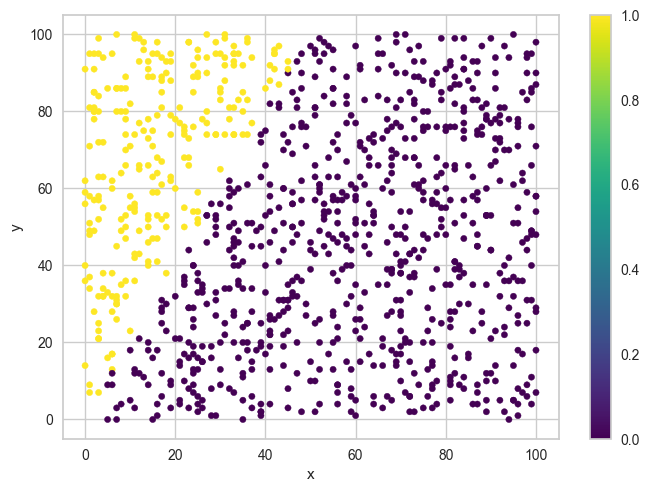

In [23]:
df.plot.scatter(x="x", y="y", c=df["label"] == "A", colormap="viridis")

In [24]:
setup(data=df, target="label", session_id=123, n_jobs=1)

,Description,Value
0,Session id,123
1,Target,label
2,Target type,Binary
3,Target mapping,"A: 0, B: 1"
4,Original data shape,"(1000, 4)"
5,Transformed data shape,"(1000, 4)"
6,Transformed train set shape,"(700, 4)"
7,Transformed test set shape,"(300, 4)"
8,Numeric features,3
9,Preprocess,True


In [25]:
best = compare_models(verbose=True)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,0.9714,0.9961,0.9714,0.9714,0.9714,0.9223,0.9223
2,0.9857,1.0000,0.9857,0.9865,0.9859,0.9619,0.9626
3,0.9857,1.0000,0.9857,0.9860,0.9856,0.9604,0.9611
4,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
5,0.9857,1.0000,0.9857,0.9860,0.9856,0.9604,0.9611
6,0.9714,1.0000,0.9714,0.9744,0.9719,0.9253,0.9279
7,0.9714,0.9979,0.9714,0.9714,0.9714,0.9252,0.9252
8,0.9571,0.9979,0.9571,0.9568,0.9567,0.8857,0.8864


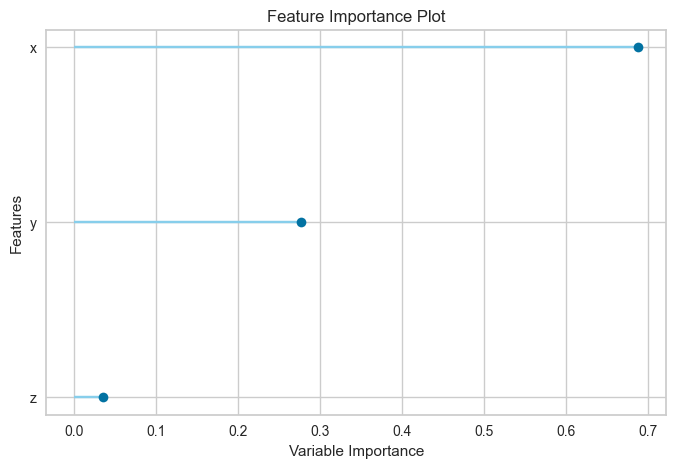

In [26]:
model = create_model("rf")
plot_model(model, plot="feature")

In [27]:
plot_model(best, plot='feature', save=True)

'Feature Importance.png'